In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

df = pd.read_csv("penguins_size.csv")
features = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
df = df.dropna(subset=features).reset_index(drop=True)
X_raw = df[features].values
mean_ = X_raw.mean(axis=0)
std_ = X_raw.std(axis=0)
X = (X_raw - mean_) / std_
y = df["species"].values
n, d = X.shape
print(n, d)
df.head()

342 4


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE


In [2]:
def log_gaussian(X, mu, Sigma):
    d = X.shape[1]
    diff = X - mu
    sign, logdet = np.linalg.slogdet(Sigma)
    sol = np.linalg.solve(Sigma, diff.T).T
    maha = np.sum(diff * sol, axis=1)
    return -0.5 * (d * np.log(2 * np.pi) + logdet + maha)

def logsumexp(a, axis=1):
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

def e_step(X, pi, mu, Sigma):
    K = len(pi)
    log_p = np.column_stack([np.log(pi[k]) + log_gaussian(X, mu[k], Sigma[k]) for k in range(K)])
    log_norm = logsumexp(log_p)
    resp = np.exp(log_p - log_norm[:, None])
    return resp, log_norm.sum()

def m_step(X, resp, reg=1e-6):
    n, d = X.shape
    Nk = resp.sum(axis=0)
    pi = Nk / n
    mu = (resp.T @ X) / Nk[:, None]
    Sigma = np.empty((len(Nk), d, d))
    for k in range(len(Nk)):
        diff = X - mu[k]
        Sigma[k] = (resp[:, k, None] * diff).T @ diff / Nk[k] + reg * np.eye(d)
    return pi, mu, Sigma

def fit_em(X, K, seed=0, max_iter=500, tol=1e-8):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    mu = X[rng.choice(n, K, replace=False)]
    Sigma = np.array([np.cov(X.T) for _ in range(K)])
    pi = np.full(K, 1 / K)
    ll_history = []
    for _ in range(max_iter):
        resp, ll = e_step(X, pi, mu, Sigma)
        ll_history.append(ll)
        pi, mu, Sigma = m_step(X, resp)
        if len(ll_history) > 1 and abs(ll_history[-1] - ll_history[-2]) < tol:
            break
    resp, ll = e_step(X, pi, mu, Sigma)
    ll_history.append(ll)
    return {"pi": pi, "mu": mu, "Sigma": Sigma, "resp": resp, "ll": ll, "history": ll_history}

In [3]:
K = 3
runs = [fit_em(X, K, seed=s) for s in range(10)]
run_table = pd.DataFrame({
    "Seed": range(10),
    "Iterations": [len(r["history"]) for r in runs],
    "Log-likelihood": [r["ll"] for r in runs]
})
best = max(runs, key=lambda r: r["ll"])
run_table

,Seed,Iterations,Log-likelihood
0,0,82,-1148.437405
1,1,54,-1159.569723
2,2,95,-1148.437405
3,3,38,-1148.437405
4,4,136,-1148.437405
5,5,37,-1148.437405
6,6,75,-1159.569723
7,7,501,-1188.485965
8,8,58,-1148.437405
9,9,46,-1195.564600


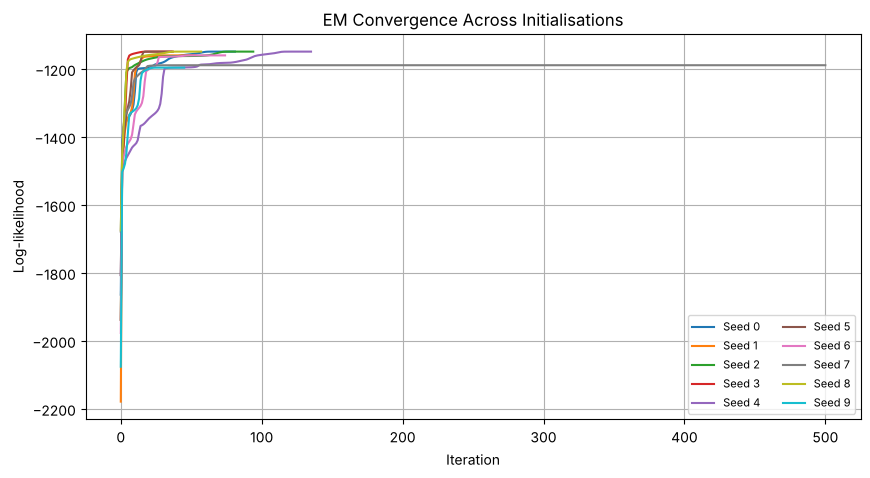

Log-likelihood non-decreasing: True


In [4]:
plt.figure(figsize=(10, 5))
for s, r in enumerate(runs):
    plt.plot(r["history"], label=f"Seed {s}")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("EM Convergence Across Initialisations")
plt.legend(ncol=2, fontsize=8)
plt.grid(True)
plt.show()

diffs = np.diff(best["history"])
print("Log-likelihood non-decreasing:", bool(np.all(diffs > -1e-9)))

In [5]:
pred = best["resp"].argmax(axis=1)
print("ARI:", round(adjusted_rand_score(y, pred), 4))
pd.crosstab(pd.Series(y, name="Species"), pd.Series(pred, name="Component"))

ARI: 0.9603


Component,0,1,2
Species,,,
Adelie,2,149,0
Chinstrap,65,3,0
Gentoo,0,0,123


In [6]:
params = pd.DataFrame({
    "Weight": best["pi"],
    **{f: best["mu"][:, i] * std_[i] + mean_[i] for i, f in enumerate(features)}
}).round(4)
params.index.name = "Component"
params

,Weight,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
Component,,,,,
0,0.1946,49.0010,18.4786,196.5158,3754.6283
1,0.4457,38.8129,18.3217,189.7066,3691.5614
2,0.3596,47.5049,14.9821,217.1870,5076.0162


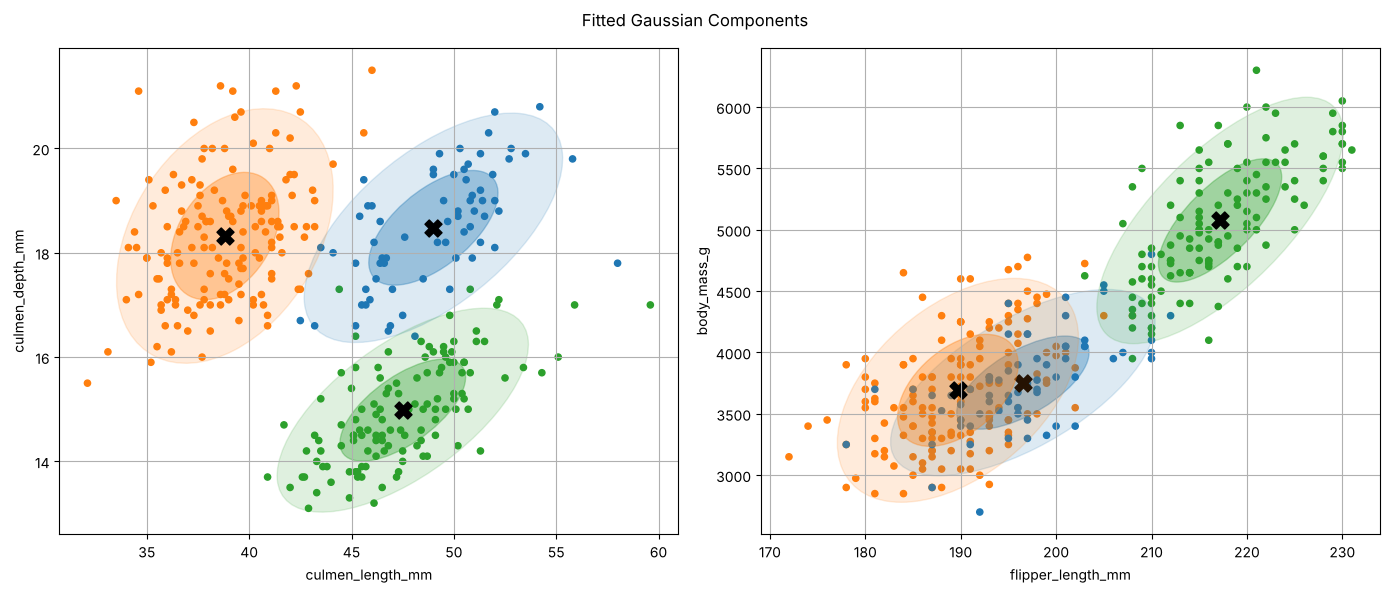

In [7]:
def draw_ellipse(ax, mu, Sigma, color):
    vals, vecs = np.linalg.eigh(Sigma)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    angle = np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0]))
    for nstd, alpha in [(1, 0.35), (2, 0.15)]:
        ax.add_patch(Ellipse(mu, 2 * nstd * np.sqrt(vals[0]), 2 * nstd * np.sqrt(vals[1]),
                             angle=angle, facecolor=color, edgecolor=color, alpha=alpha))

pairs = [(0, 1), (2, 3)]
colors = ["tab:blue", "tab:orange", "tab:green"]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
scale = np.diag(std_)
for ax, (i, j) in zip(axes, pairs):
    ax.scatter(X_raw[:, i], X_raw[:, j], c=[colors[p] for p in pred], s=20)
    for k in range(K):
        mu_k = best["mu"][k] * std_ + mean_
        S_k = scale @ best["Sigma"][k] @ scale
        draw_ellipse(ax, mu_k[[i, j]], S_k[np.ix_([i, j], [i, j])], colors[k])
        ax.scatter(*mu_k[[i, j]], marker="X", s=150, c="black")
    ax.set_xlabel(features[i])
    ax.set_ylabel(features[j])
    ax.grid(True)
plt.suptitle("Fitted Gaussian Components")
plt.tight_layout()
plt.show()

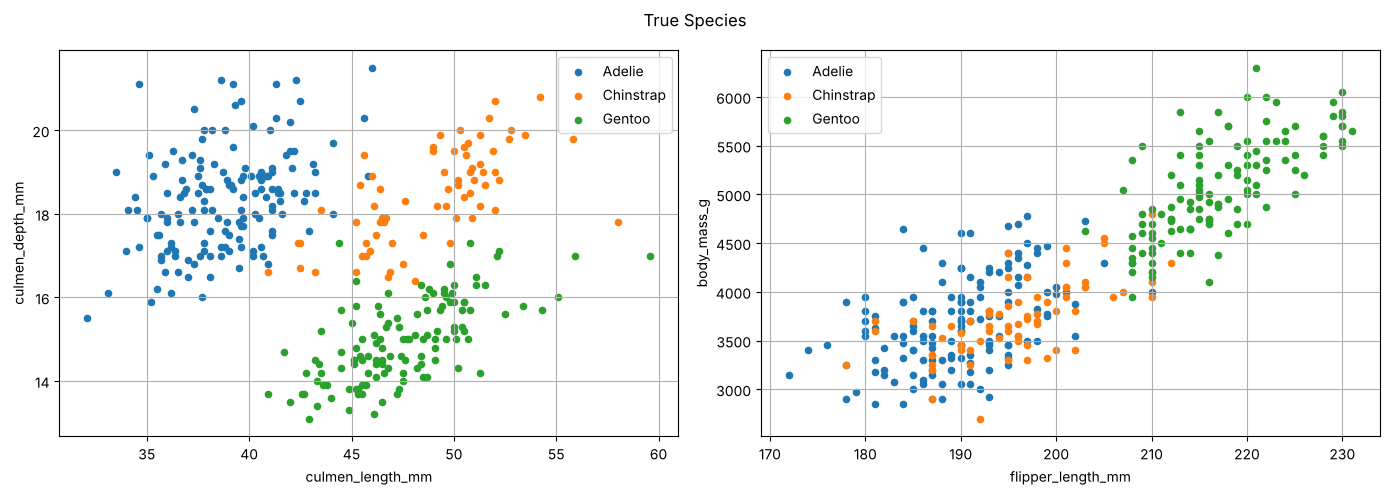

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (i, j) in zip(axes, pairs):
    for sp in np.unique(y):
        m = y == sp
        ax.scatter(X_raw[m, i], X_raw[m, j], s=20, label=sp)
    ax.set_xlabel(features[i])
    ax.set_ylabel(features[j])
    ax.legend()
    ax.grid(True)
plt.suptitle("True Species")
plt.tight_layout()
plt.show()

In [9]:
skl = GaussianMixture(n_components=3, covariance_type="full", n_init=10, random_state=0).fit(X)
skl_pred = skl.predict(X)
comparison = pd.DataFrame({
    "Log-likelihood": [best["ll"], skl.score(X) * n],
    "ARI vs species": [adjusted_rand_score(y, pred), adjusted_rand_score(y, skl_pred)],
    "ARI vs sklearn": [adjusted_rand_score(skl_pred, pred), 1.0],
}, index=["Scratch EM", "sklearn"])
comparison

,Log-likelihood,ARI vs species,ARI vs sklearn
Scratch EM,-1148.437405,0.960306,1.0
sklearn,-1148.442443,0.960306,1.0


In [10]:
def n_params(K, d):
    return K * d + K * d * (d + 1) // 2 + (K - 1)

rows = []
for k in range(1, 7):
    r = max([fit_em(X, k, seed=s) for s in range(10)], key=lambda r: r["ll"])
    p = n_params(k, d)
    rows.append({"K": k, "Log-likelihood": r["ll"], "AIC": -2 * r["ll"] + 2 * p, "BIC": -2 * r["ll"] + p * np.log(n)})
ic = pd.DataFrame(rows).set_index("K")
print("Best K by BIC:", ic["BIC"].idxmin(), "| Best K by AIC:", ic["AIC"].idxmin())
ic

Best K by BIC: 3 | Best K by AIC: 6


,Log-likelihood,AIC,BIC
K,,,
1,-1518.152278,3064.304556,3117.991906
2,-1208.794617,2475.589234,2586.798745
3,-1148.437405,2384.874810,2553.606483
4,-1116.195786,2350.391572,2576.645406
5,-1097.486306,2342.972611,2626.748606
6,-1080.741054,2339.482107,2680.780263


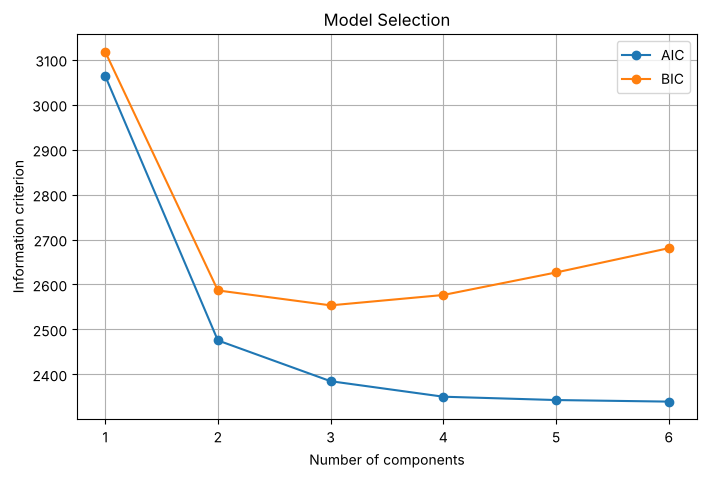

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(ic.index, ic["AIC"], marker="o", label="AIC")
plt.plot(ic.index, ic["BIC"], marker="o", label="BIC")
plt.xlabel("Number of components")
plt.ylabel("Information criterion")
plt.title("Model Selection")
plt.legend()
plt.grid(True)
plt.show()

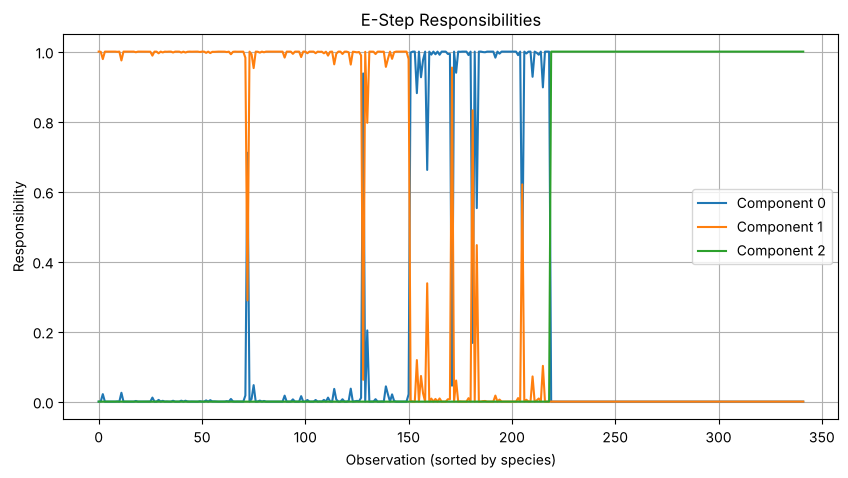

In [12]:
plt.figure(figsize=(10, 5))
order = np.argsort(y, kind="stable")
for k in range(K):
    plt.plot(best["resp"][order, k], label=f"Component {k}")
plt.xlabel("Observation (sorted by species)")
plt.ylabel("Responsibility")
plt.title("E-Step Responsibilities")
plt.legend()
plt.grid(True)
plt.show()